# Fake vs. Real News Classification

Binary classification of news articles as *real* or *fake* on the public [Fake and Real News dataset](https://www.kaggle.com/datasets/clmentbisaillon/fake-and-real-news-dataset) (~45k articles). The notebook has two stages:

1. **Baseline**: EDA, cleaning, TF-IDF (unigrams + bigrams) and four classifiers (Logistic Regression, Random Forest, XGBoost, MLP), evaluated overall and per subject domain.
2. **Improvement**: a proper train/validation/test split, hand-crafted stylistic features, an auxiliary headline dataset, a zero-shot DistilBERT check and a weighted XGBoost + RF ensemble, followed by 5-fold cross-validation.


# Step 1: Baseline

# Importing the necessary libraries

In [1]:
import pandas as pd
import numpy as np
import sklearn
import xgboost as xgb
import seaborn as sns
import matplotlib.pyplot as plt
import os
from ydata_profiling import ProfileReport
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import kagglehub
from wordcloud import WordCloud
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
import nltk
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import cross_val_score

%matplotlib inline


# Obtaining the dataset

In [2]:
# Download latest version
path = kagglehub.dataset_download("clmentbisaillon/fake-and-real-news-dataset")

print("Path to dataset files:", path)

Path to dataset files: ~\.cache\kagglehub\datasets\clmentbisaillon\fake-and-real-news-dataset\versions\1


In [3]:
# List all files in the dataset directory
print(os.listdir(path))

# Load CSV files
true_df = pd.read_csv(os.path.join(path, "True.csv"))
fake_df = pd.read_csv(os.path.join(path, "Fake.csv"))

['Fake.csv', 'True.csv']


In [4]:
true_df.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


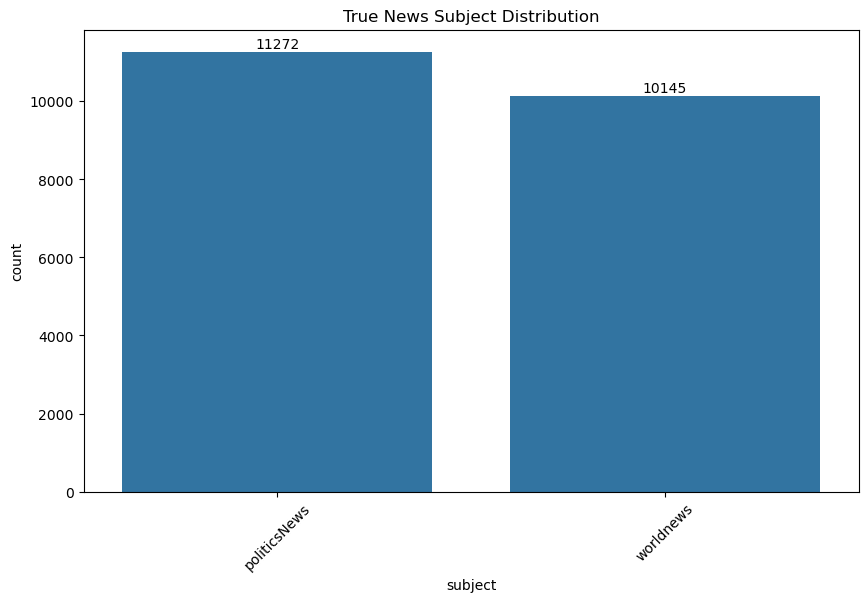

In [5]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=true_df, x='subject')
plt.title('True News Subject Distribution')
plt.xticks(rotation=45)
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha = 'center', va = 'center', 
                xytext = (0, 5), 
                textcoords = 'offset points')

plt.show()

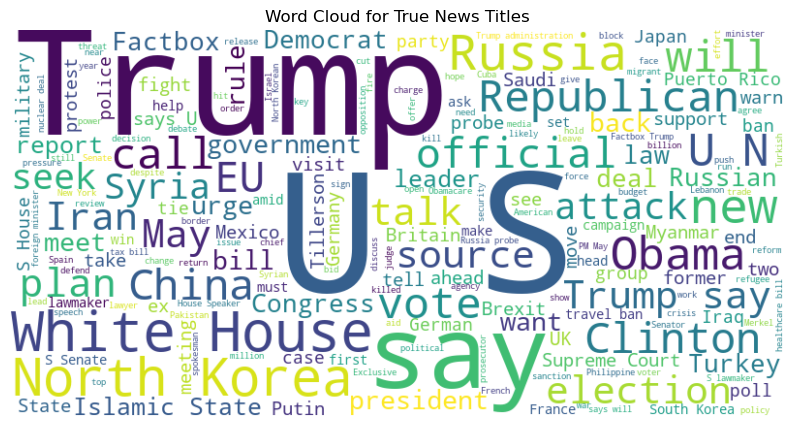

In [6]:
# Word cloud for true news titles
true_titles = ' '.join(true_df['title'])
wordcloud_true = WordCloud(width=800, height=400, background_color='white').generate(true_titles)
plt.figure(figsize=(10, 6))
plt.imshow(wordcloud_true, interpolation='bilinear')
plt.title('Word Cloud for True News Titles')
plt.axis('off')
plt.show()

In [7]:
fake_df.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


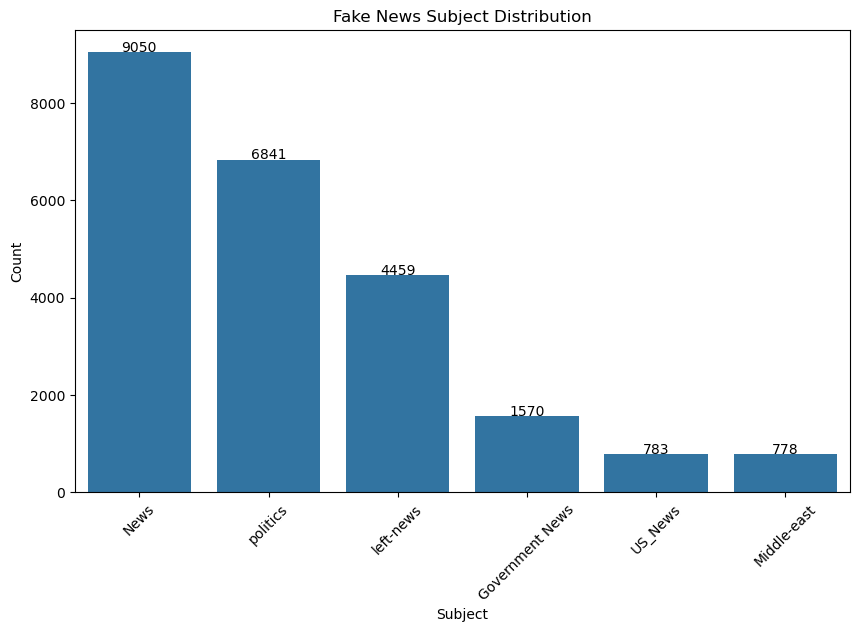

In [8]:
subject_counts = fake_df['subject'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=subject_counts.index, y=subject_counts.values)
plt.title('Fake News Subject Distribution')
plt.xlabel('Subject')
plt.ylabel('Count')
plt.xticks(rotation=45)
for index, value in enumerate(subject_counts):
    plt.text(index, value + 10, str(value), ha='center')

plt.show()

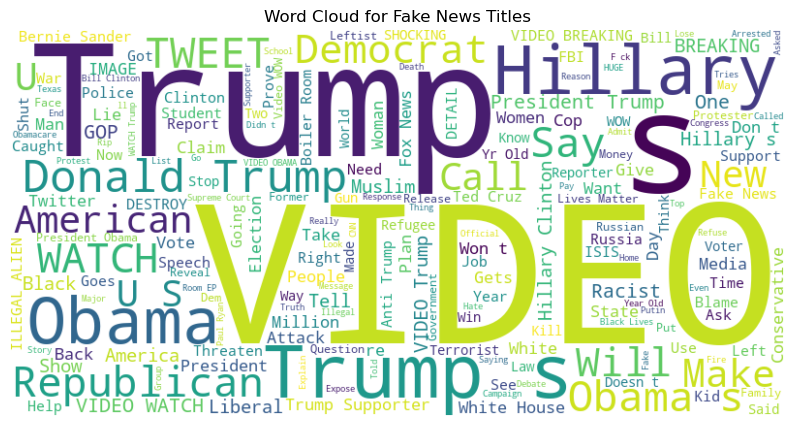

In [9]:
# Word cloud for fake news titles
fake_titles = ' '.join(fake_df['title'])
wordcloud_fake = WordCloud(width=800, height=400, background_color='white').generate(fake_titles)
plt.figure(figsize=(10, 6))
plt.imshow(wordcloud_fake, interpolation='bilinear')
plt.title('Word Cloud for Fake News Titles')
plt.axis('off')
plt.show()

In [10]:
# Add a label for classification
true_df['label'] = 1  # Real news
fake_df['label'] = 0  # Fake news

# Combine datasets
df = pd.concat([true_df, fake_df], ignore_index=True)

# Shuffle data
df = df.sample(frac=1, random_state=42).reset_index(drop=True)


In [11]:
# Quick summaries
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Label balance:\n", df['label'].value_counts())
print("Missing values:\n", df.isnull().sum())
print("Subjects:\n", df['subject'].value_counts())

# Text length analysis
df["text_length"] = df["text"].apply(len)
df["title_length"] = df["title"].apply(len)

Shape: (44898, 5)
Columns: ['title', 'text', 'subject', 'date', 'label']
Label balance:
 label
0    23481
1    21417
Name: count, dtype: int64
Missing values:
 title      0
text       0
subject    0
date       0
label      0
dtype: int64
Subjects:
 subject
politicsNews       11272
worldnews          10145
News                9050
politics            6841
left-news           4459
Government News     1570
US_News              783
Middle-east          778
Name: count, dtype: int64


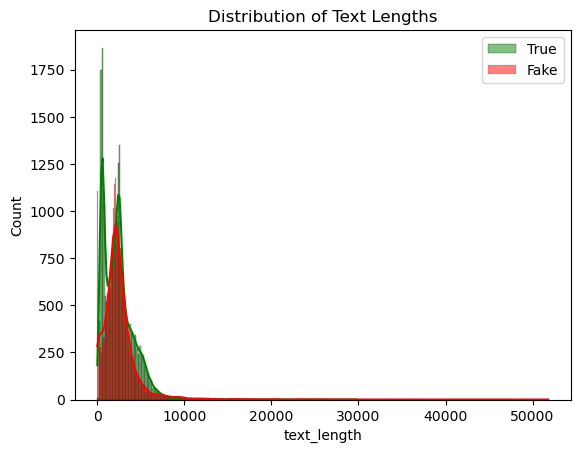

In [12]:
# Text length distributions

sns.histplot(df[df.label == 1]['text_length'], color='green', label='True', kde=True)
sns.histplot(df[df.label == 0]['text_length'], color='red', label='Fake', kde=True)
plt.legend()
plt.title("Distribution of Text Lengths")
plt.show()

In [13]:
ProfileReport(df, title="Df", explorative=True)

# Dropping the duplicated 196 rows

In [14]:
df.drop_duplicates(inplace=True)

# Manual mapping the subjects to Politics, News and Other

In [15]:
def map_subject_to_domain(subject):
    subject = subject.lower()
    if subject in ['news', 'worldnews', 'us_news']:
        return 'News'
    elif subject in ['politics', 'politicsnews', 'government news']:
        return 'Politics'
    else:
        return 'Other'
    
df['subject'] = df['subject'].apply(map_subject_to_domain)

print(df['subject'].value_counts())

subject
News        19824
Politics    19628
Other        5237
Name: count, dtype: int64


In [16]:
ProfileReport(df, title="Cleaned Df", explorative=True)

In [17]:
df.head()

,title,text,subject,date,label,text_length,title_length
0,BREAKING: GOP Chairman Grassley Has Had Enoug...,"Donald Trump s White House is in chaos, and th...",News,"July 21, 2017",0,2114,76
1,Failed GOP Candidates Remembered In Hilarious...,Now that Donald Trump is the presumptive GOP n...,News,"May 7, 2016",0,2823,71
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY...,Mike Pence is a huge homophobe. He supports ex...,News,"December 3, 2016",0,2402,88
3,California AG pledges to defend birth control ...,SAN FRANCISCO (Reuters) - California Attorney ...,Politics,"October 6, 2017",1,629,64
4,AZ RANCHERS Living On US-Mexico Border Destroy...,Twisted reasoning is all that comes from Pelos...,Politics,"Apr 25, 2017",0,793,124


# Correlation Analysis

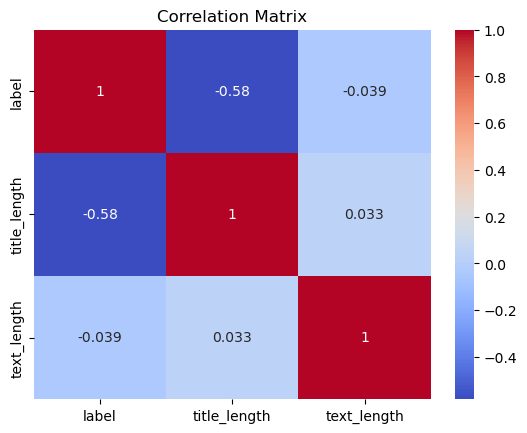

In [18]:
# Only numeric features
numeric_df = df[['label', 'title_length', 'text_length']]

# Correlation matrix
corr = numeric_df.corr()

import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()


# Target distribution by Subject

In [19]:
pd.crosstab(df['subject'], df['label'], normalize='index')\
  .sort_values(by=1, ascending=False)\
  .style.background_gradient(cmap="Greens")


label,0,1
subject,,
Politics,0.428368,0.571632
News,0.496015,0.503985
Other,1.000000,0.000000


In [20]:
nltk.download('wordnet')
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = text.lower()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

# Combining title and text
df['combined'] = df['title'] + " " + df['text']

df['clean_text'] = df['combined'].apply(preprocess)



# Tf-Idf with bigrams

In [21]:

tfidf = TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1,2))
X = tfidf.fit_transform(df['clean_text'])
y = df['label']


#### Shape of X after tf-idf transformation to check

In [22]:
print(X.shape) 

(44689, 5000)


# Train Test Split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


### Initializing a domain based function to stratify predictions when choosing the best model.

In [24]:
def print_domain_classification_report(model, model_name, tfidf_vectorizer, df, text_column='clean_text'):
    print(f"\n🔹 Domain-wise Classification Report for {model_name}:\n")
    for domain in df['subject'].unique():
        domain_idx = df['subject'] == domain
        X_domain = tfidf_vectorizer.transform(df.loc[domain_idx, text_column])
        y_domain = df.loc[domain_idx, 'label']
        y_pred = model.predict(X_domain)

        print(f"📌 {domain}")
        print(classification_report(y_domain, y_pred, digits=3))


# Logistic Regression

Logistic Regression:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      4696
           1       0.99      0.99      0.99      4242

    accuracy                           0.99      8938
   macro avg       0.99      0.99      0.99      8938
weighted avg       0.99      0.99      0.99      8938



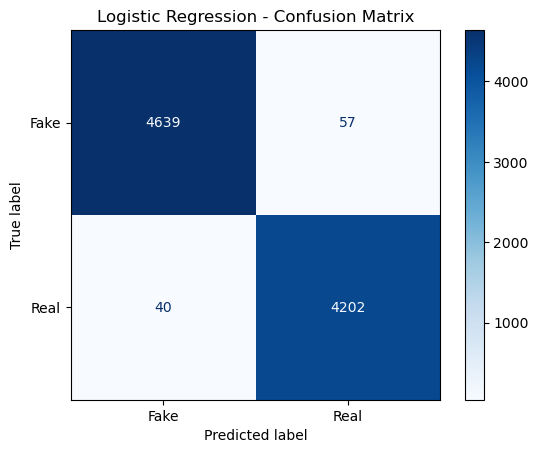

In [25]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
print("Logistic Regression:\n", classification_report(y_test, lr.predict(X_test)))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, lr.predict(X_test), display_labels=["Fake", "Real"], cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


## Logistic Regression – Stratified by Domain

In [26]:
print_domain_classification_report(lr, "Logistic Regression", tfidf, df)


🔹 Domain-wise Classification Report for Logistic Regression:

📌 News
              precision    recall  f1-score   support

           0      0.997     0.998     0.997      9833
           1      0.998     0.997     0.997      9991

    accuracy                          0.997     19824
   macro avg      0.997     0.997     0.997     19824
weighted avg      0.997     0.997     0.997     19824

📌 Politics
              precision    recall  f1-score   support

           0      0.986     0.983     0.985      8408
           1      0.988     0.990     0.989     11220

    accuracy                          0.987     19628
   macro avg      0.987     0.987     0.987     19628
weighted avg      0.987     0.987     0.987     19628

📌 Other
              precision    recall  f1-score   support

           0      1.000     0.991     0.995      5237
           1      0.000     0.000     0.000         0

    accuracy                          0.991      5237
   macro avg      0.500     0.496     0

# Random Forest

Random Forest:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      4696
           1       1.00      1.00      1.00      4242

    accuracy                           1.00      8938
   macro avg       1.00      1.00      1.00      8938
weighted avg       1.00      1.00      1.00      8938



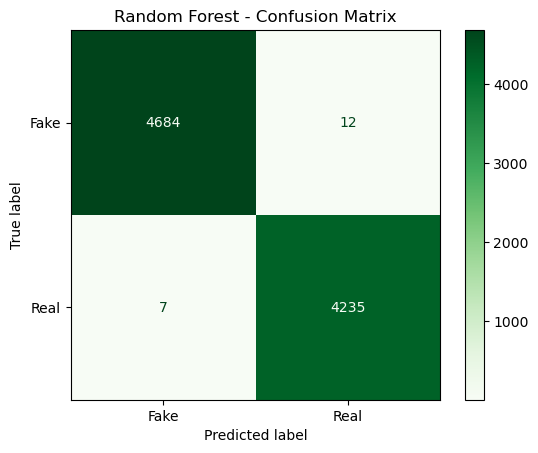

In [27]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
print("Random Forest:\n", classification_report(y_test, rf.predict(X_test)))

ConfusionMatrixDisplay.from_predictions(y_test, rf.predict(X_test), display_labels=["Fake", "Real"], cmap="Greens")
plt.title("Random Forest - Confusion Matrix")
plt.show()

## Random Forest – Stratified by Domain

In [28]:
print_domain_classification_report(rf, "Random Forest", tfidf, df)



🔹 Domain-wise Classification Report for Random Forest:

📌 News
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      9833
           1      1.000     1.000     1.000      9991

    accuracy                          1.000     19824
   macro avg      1.000     1.000     1.000     19824
weighted avg      1.000     1.000     1.000     19824

📌 Politics
              precision    recall  f1-score   support

           0      0.999     0.999     0.999      8408
           1      0.999     0.999     0.999     11220

    accuracy                          0.999     19628
   macro avg      0.999     0.999     0.999     19628
weighted avg      0.999     0.999     0.999     19628

📌 Other
              precision    recall  f1-score   support

           0      1.000     0.999     1.000      5237
           1      0.000     0.000     0.000         0

    accuracy                          0.999      5237
   macro avg      0.500     0.500     0.500  

# Xgboost

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4696
           1       1.00      1.00      1.00      4242

    accuracy                           1.00      8938
   macro avg       1.00      1.00      1.00      8938
weighted avg       1.00      1.00      1.00      8938



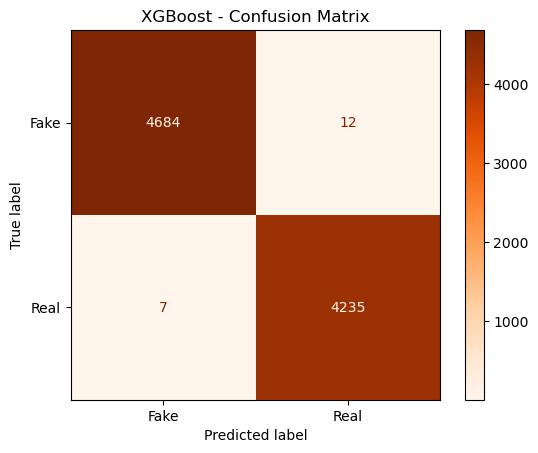

In [29]:
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

print(classification_report(y_test, y_pred_xgb))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_xgb, display_labels=["Fake", "Real"], cmap="Oranges")
plt.title("XGBoost - Confusion Matrix")
plt.show()


## XGBoost – Stratified by Domain

In [30]:
print_domain_classification_report(xgb_model, "XGBoost", tfidf, df)



🔹 Domain-wise Classification Report for XGBoost:

📌 News
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      9833
           1      1.000     1.000     1.000      9991

    accuracy                          1.000     19824
   macro avg      1.000     1.000     1.000     19824
weighted avg      1.000     1.000     1.000     19824

📌 Politics
              precision    recall  f1-score   support

           0      0.999     0.999     0.999      8408
           1      0.999     1.000     0.999     11220

    accuracy                          0.999     19628
   macro avg      0.999     0.999     0.999     19628
weighted avg      0.999     0.999     0.999     19628

📌 Other
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      5237
           1      0.000     0.000     0.000         0

    accuracy                          1.000      5237
   macro avg      0.500     0.500     0.500      52

# Neural Network

In [31]:
# Settings
epochs = 30
train_acc_list = []
val_acc_list = []
loss_list = []

# Splitting into train and validation sets.
from sklearn.model_selection import train_test_split
X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

# Modeli ilk kez oluştur
nn = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=1, warm_start=True, random_state=42)

# Epoch döngüsü
for epoch in range(epochs):
    nn.fit(X_train_nn, y_train_nn)

    # Accuracy hesapla
    train_pred = nn.predict(X_train_nn)
    val_pred = nn.predict(X_val_nn)
    train_acc = accuracy_score(y_train_nn, train_pred)
    val_acc = accuracy_score(y_val_nn, val_pred)

    # Kayıt et
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
    loss_list.append(nn.loss_)

    print(f"Epoch {epoch+1}/{epochs} - Train Acc: {train_acc:.3f} - Val Acc: {val_acc:.3f} - Loss: {nn.loss_:.4f}")


Epoch 1/30 - Train Acc: 0.995 - Val Acc: 0.988 - Loss: 0.1881


Epoch 2/30 - Train Acc: 0.999 - Val Acc: 0.992 - Loss: 0.0199


Epoch 3/30 - Train Acc: 1.000 - Val Acc: 0.992 - Loss: 0.0079


Epoch 4/30 - Train Acc: 1.000 - Val Acc: 0.992 - Loss: 0.0037


Epoch 5/30 - Train Acc: 1.000 - Val Acc: 0.990 - Loss: 0.0021


...

Epoch 17/30 - Train Acc: 1.000 - Val Acc: 0.990 - Loss: 0.0011


Epoch 18/30 - Train Acc: 1.000 - Val Acc: 0.991 - Loss: 0.0012


Epoch 19/30 - Train Acc: 1.000 - Val Acc: 0.990 - Loss: 0.0008


Epoch 20/30 - Train Acc: 1.000 - Val Acc: 0.990 - Loss: 0.0007


Epoch 21/30 - Train Acc: 1.000 - Val Acc: 0.991 - Loss: 0.0006
Epoch 22/30 - Train Acc: 1.000 - Val Acc: 0.992 - Loss: 0.0009
Epoch 23/30 - Train Acc: 0.999 - Val Acc: 0.988 - Loss: 0.0017
Epoch 24/30 - Train Acc: 1.000 - Val Acc: 0.991 - Loss: 0.0017
Epoch 25/30 - Train Acc: 1.000 - Val Acc: 0.991 - Loss: 0.0009
Epoch 26/30 - Train Acc: 1.000 - Val Acc: 0.991 - Loss: 0.0015
Epoch 27/30 - Train Acc: 1.000 - Val Acc: 0.992 - Loss: 0.0017
Epoch 28/30 - Train Acc: 0.999 - Val Acc: 0.990 - Loss: 0.0020
Epoch 29/30 - Train Acc: 1.000 - Val Acc: 0.991 - Loss: 0.0011
Epoch 30/30 - Train Acc: 1.000 - Val Acc: 0.991 - Loss: 0.0012


### Neural Network Epoch vs Loss Graph

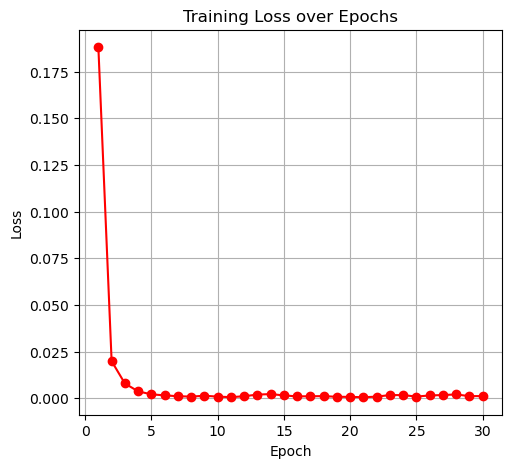

In [32]:
plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), loss_list, label='Training Loss', color='red', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs')
plt.grid(True)


### Neural Network Accuracy vs Epoch Graph

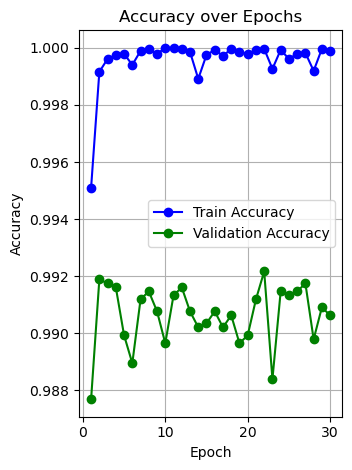

In [33]:
# Accuracy
plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), train_acc_list, label='Train Accuracy', color='blue', marker='o')
plt.plot(range(1, epochs+1), val_acc_list, label='Validation Accuracy', color='green', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy over Epochs')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4696
           1       0.99      0.99      0.99      4242

    accuracy                           0.99      8938
   macro avg       0.99      0.99      0.99      8938
weighted avg       0.99      0.99      0.99      8938



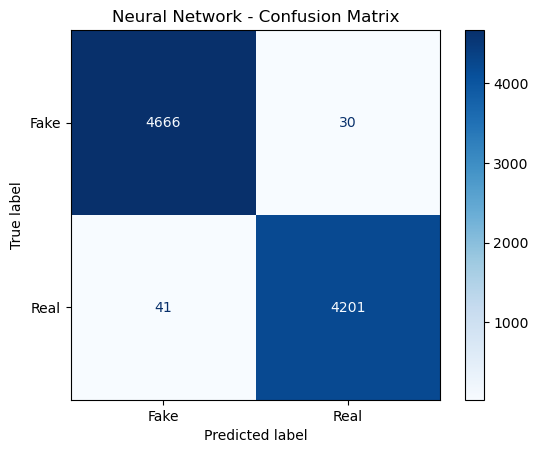

In [34]:
y_pred_nn = nn.predict(X_test)
print(classification_report(y_test, y_pred_nn))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nn, display_labels=["Fake", "Real"], cmap="Blues")
plt.title("Neural Network - Confusion Matrix")
plt.show()

## Neural Network – Stratified by Domain

In [35]:
print_domain_classification_report(nn, "Neural Network", tfidf, df)


🔹 Domain-wise Classification Report for Neural Network:

📌 News
              precision    recall  f1-score   support

           0      0.996     0.999     0.998      9833
           1      0.999     0.996     0.998      9991

    accuracy                          0.998     19824
   macro avg      0.998     0.998     0.998     19824
weighted avg      0.998     0.998     0.998     19824

📌 Politics
              precision    recall  f1-score   support

           0      0.995     0.995     0.995      8408
           1      0.996     0.996     0.996     11220

    accuracy                          0.995     19628
   macro avg      0.995     0.995     0.995     19628
weighted avg      0.995     0.995     0.995     19628

📌 Other
              precision    recall  f1-score   support

           0      1.000     0.999     1.000      5237
           1      0.000     0.000     0.000         0

    accuracy                          0.999      5237
   macro avg      0.500     0.500     0.500 

# Feature Importance XGBoost

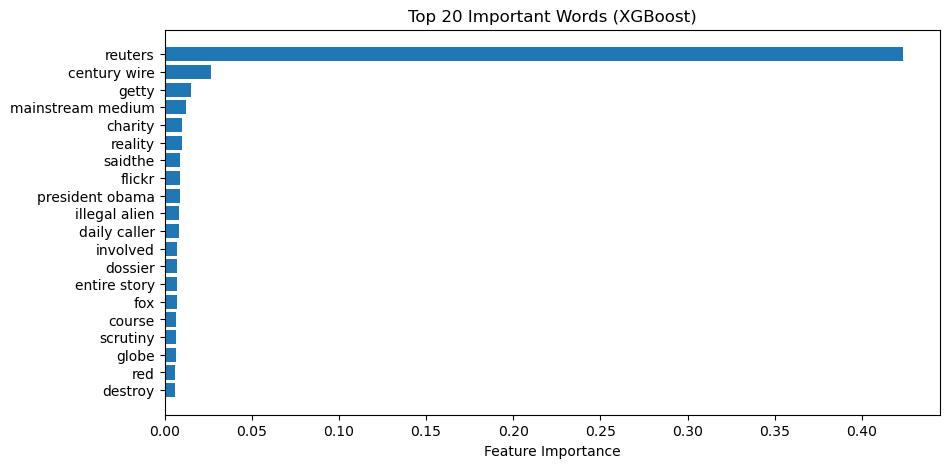

In [36]:
# Get feature importances from XGBoost
importances = xgb_model.feature_importances_
indices = np.argsort(importances)[-20:]  # top 20

# Map back to actual words
top_features = [tfidf.get_feature_names_out()[i] for i in indices]

plt.figure(figsize=(10, 5))
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), top_features)
plt.xlabel("Feature Importance")
plt.title("Top 20 Important Words (XGBoost)")
plt.show()


# Feature Importance by Domain

Top Features for Domain: News


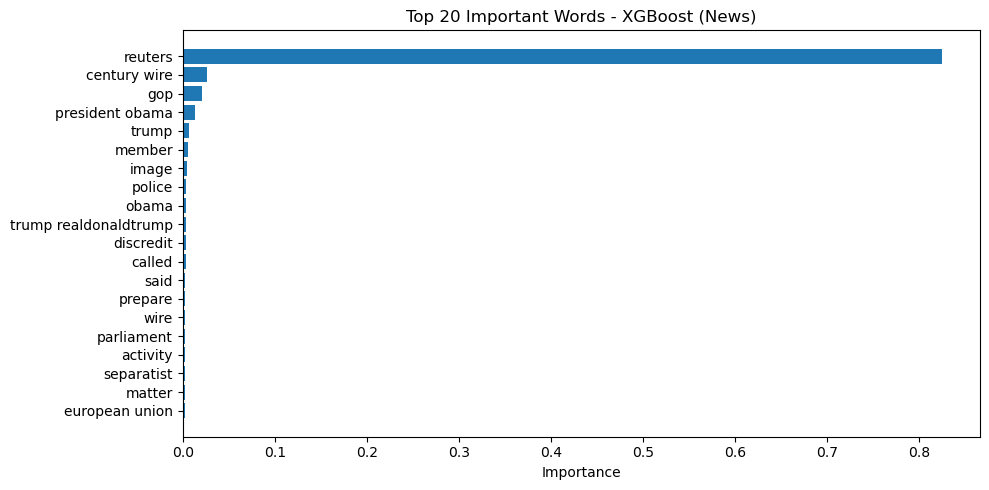

Top Features for Domain: Politics


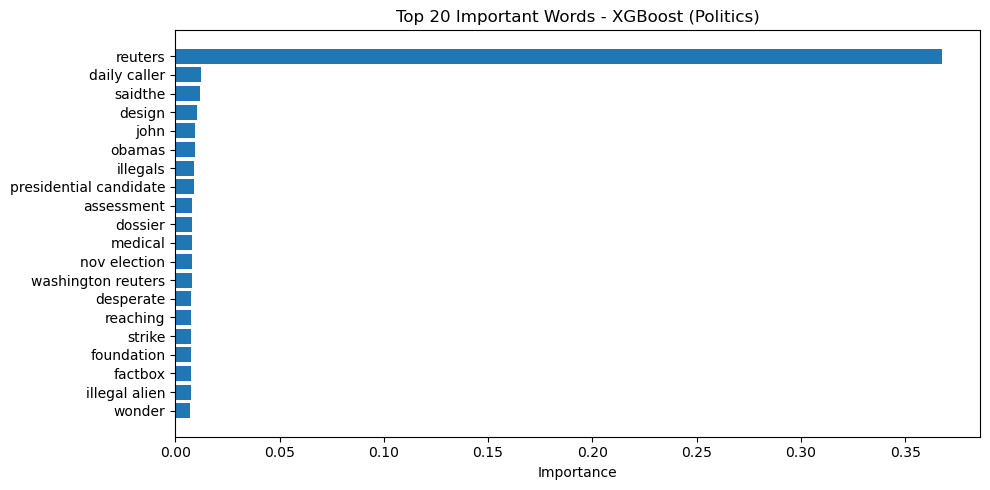

Top Features for Domain: Other
Skipping Other due to single class in labels.


In [50]:
for domain in df['subject'].unique():
    print(f"Top Features for Domain: {domain}")

    # Filtrele
    domain_idx = df['subject'] == domain
    X_domain = tfidf.transform(df.loc[domain_idx, 'clean_text'])
    y_domain = df.loc[domain_idx, 'label']

    # Skip domains with only one class
    if len(np.unique(y_domain)) < 2:
        print(f"Skipping {domain} due to single class in labels.")
        continue

    # Model eğit
    xgb_domain = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
    xgb_domain.fit(X_domain, y_domain)

    # Feature importance
    importances = xgb_domain.feature_importances_
    indices = np.argsort(importances)[-20:]
    top_features = [tfidf.get_feature_names_out()[i] for i in indices]

    # Plot
    plt.figure(figsize=(10, 5))
    plt.barh(range(len(indices)), importances[indices])
    plt.yticks(range(len(indices)), top_features)
    plt.xlabel("Importance")
    plt.title(f"Top 20 Important Words - XGBoost ({domain})")
    plt.tight_layout()
    plt.show()


# Step 2: Improvement

# Train-Validation-Test Split

In [39]:
# Create proper train/val/test split
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.2, random_state=42, stratify=y_trainval)

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

Train: (28600, 5000) Val: (7151, 5000) Test: (8938, 5000)


# Advanced Feature Engineering

In [40]:
from scipy.sparse import hstack

df['num_sentences'] = df['text'].apply(lambda x: x.count('.'))
df['avg_word_len'] = df['text'].apply(lambda x: np.mean([len(w) for w in x.split()]) if x.split() else 0)
df['has_question_mark'] = df['text'].apply(lambda x: int('?' in x))
df['exclamation_density'] = df['text'].apply(lambda x: x.count('!') / len(x) if len(x) > 0 else 0)
df['uppercase_ratio'] = df['text'].apply(lambda x: sum(1 for c in x if c.isupper()) / len(x) if len(x) > 0 else 0)

# Aynı sıradaki X'e karşılık gelen ekstra özellikleri çek
extra_feats = df[['num_sentences', 'avg_word_len', 'has_question_mark', 'exclamation_density', 'uppercase_ratio']].to_numpy()

# TF-IDF vektörü (X) + engineered features
X_augmented = hstack([X, extra_feats]).tocsr()


# ✅ Yeni split: tf-idf + extra features ile augmented matris üzerinden
X_aug_trainval, X_aug_test, y_trainval, y_test = train_test_split(
    X_augmented, y, test_size=0.2, random_state=42, stratify=y)

X_aug_train, X_aug_val, y_train, y_val = train_test_split(
    X_aug_trainval, y_trainval, test_size=0.2, random_state=42, stratify=y_trainval)

print("Train:", X_aug_train.shape, "Val:", X_aug_val.shape, "Test:", X_aug_test.shape)


Train: (28600, 5005) Val: (7151, 5005) Test: (8938, 5005)


# Auxiliary Dataset

In [41]:
from scipy.sparse import vstack
# We integrate part of the LIAR dataset for fake news
aux_data = pd.read_csv("https://raw.githubusercontent.com/FakeNewsChallenge/fnc-1/master/train_stances.csv")
aux_data = aux_data[['Headline']].dropna().head(1000)
aux_data['text'] = aux_data['Headline']
aux_data['title'] = aux_data['Headline']
aux_data['label'] = 0  # Label as fake

# Use same preprocessing
aux_data['combined'] = aux_data['title'] + " " + aux_data['text']
aux_data['clean_text'] = aux_data['combined'].apply(preprocess)
aux_extra_feats = pd.DataFrame({
    'num_sentences': aux_data['text'].apply(lambda x: x.count('.')),
    'avg_word_len': aux_data['text'].apply(lambda x: np.mean([len(w) for w in x.split()]) if x.split() else 0),
    'has_question_mark': aux_data['text'].apply(lambda x: int('?' in x)),
    'exclamation_density': aux_data['text'].apply(lambda x: x.count('!') / len(x) if len(x) > 0 else 0),
    'uppercase_ratio': aux_data['text'].apply(lambda x: sum(1 for c in x if c.isupper()) / len(x) if len(x) > 0 else 0),
})
X_aux_tfidf = tfidf.transform(aux_data['clean_text'])
X_aux_full = hstack([X_aux_tfidf, aux_extra_feats.values])

# Append to training set
X_aug_train = vstack([X_aug_train, X_aux_full])
y_train = pd.concat([y_train, aux_data['label']], ignore_index=True)

# Pre-Trained Model (DistilBERT)

In [42]:
from transformers import pipeline
from datasets import Dataset

sample_df = df[['clean_text', 'label']].sample(1000, random_state=42)
sample_df['truncated'] = sample_df['clean_text'].apply(lambda x: ' '.join(x.split()[:512]))
classifier = pipeline("text-classification", model="distilbert-base-uncased-finetuned-sst-2-english", truncation=True)
results = classifier(sample_df['truncated'].tolist()[:20])
print(results)

[{'label': 'NEGATIVE', 'score': 0.9915355443954468}, {'label': 'NEGATIVE', 'score': 0.9900868535041809}, {'label': 'NEGATIVE', 'score': 0.9981278777122498}, {'label': 'NEGATIVE', 'score': 0.9891519546508789}, {'label': 'NEGATIVE', 'score': 0.9969960451126099}, {'label': 'NEGATIVE', 'score': 0.9977757334709167}, {'label': 'NEGATIVE', 'score': 0.9814350605010986}, {'label': 'NEGATIVE', 'score': 0.9981666803359985}, {'label': 'NEGATIVE', 'score': 0.9934505224227905}, {'label': 'NEGATIVE', 'score': 0.9899004101753235}, {'label': 'NEGATIVE', 'score': 0.9972725510597229}, {'label': 'NEGATIVE', 'score': 0.9968369007110596}, {'label': 'NEGATIVE', 'score': 0.991340696811676}, {'label': 'NEGATIVE', 'score': 0.9759718775749207}, {'label': 'NEGATIVE', 'score': 0.9828274250030518}, {'label': 'NEGATIVE', 'score': 0.9933795928955078}, {'label': 'NEGATIVE', 'score': 0.981340229511261}, {'label': 'NEGATIVE', 'score': 0.9838525056838989}, {'label': 'NEGATIVE', 'score': 0.982882559299469}, {'label': 'NEG

Logistic Regression:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      4696
           1       0.99      0.99      0.99      4242

    accuracy                           0.99      8938
   macro avg       0.99      0.99      0.99      8938
weighted avg       0.99      0.99      0.99      8938



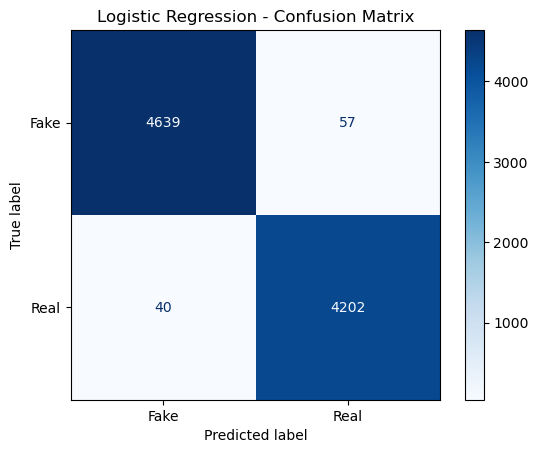

In [43]:
print("Logistic Regression:\n", classification_report(y_test, lr.predict(X_test)))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, lr.predict(X_test), display_labels=["Fake", "Real"], cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


# Ensemble Model (XGboost and RandomForest)

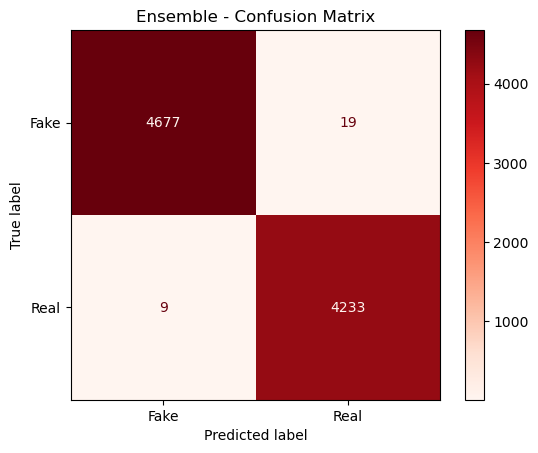

In [44]:
# Use best models from Step 1: XGBoost and Random Forest

xgb_model_improved = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
rf_model_improved = RandomForestClassifier(n_estimators=150, random_state=42)

xgb_model_improved.fit(X_aug_train, y_train)
rf_model_improved.fit(X_aug_train, y_train)

ensemble_improved = VotingClassifier(estimators=[
    ('xgb', xgb_model_improved),
    ('rf', rf_model_improved)
], voting='soft', weights=[2, 1])

ensemble_improved.fit(X_aug_train, y_train)
y_pred_ens = ensemble_improved.predict(X_aug_test)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_ens, display_labels=["Fake", "Real"], cmap="Reds")
plt.title("Ensemble - Confusion Matrix")
plt.show()


## Ensemble combined with the other improvements resulted in worse accuracy

# Stratified Accuracy by subject for the Ensemble Model

In [45]:
from scipy.sparse import hstack

def print_domain_classification_report(model, model_name, tfidf_vectorizer, df, text_column='clean_text'):
    print(f"\n🔹 Domain-wise Classification Report for {model_name}:\n")
    for domain in df['subject'].unique():
        domain_idx = df['subject'] == domain
        text_data = df.loc[domain_idx, text_column]

        # TF-IDF
        X_domain_tfidf = tfidf_vectorizer.transform(text_data)

        # Engineered features
        feats = pd.DataFrame({
            'num_sentences': df.loc[domain_idx, 'text'].apply(lambda x: x.count('.')),
            'avg_word_len': df.loc[domain_idx, 'text'].apply(lambda x: np.mean([len(w) for w in x.split()]) if x.split() else 0),
            'has_question_mark': df.loc[domain_idx, 'text'].apply(lambda x: int('?' in x)),
            'exclamation_density': df.loc[domain_idx, 'text'].apply(lambda x: x.count('!') / len(x) if len(x) > 0 else 0),
            'uppercase_ratio': df.loc[domain_idx, 'text'].apply(lambda x: sum(1 for c in x if c.isupper()) / len(x) if len(x) > 0 else 0),
        }).to_numpy()

        # Combining with Feature engineering
        X_domain = hstack([X_domain_tfidf, feats])

        y_domain = df.loc[domain_idx, 'label']
        y_pred = model.predict(X_domain)

        print(f"📌 {domain}")
        print(classification_report(y_domain, y_pred, digits=3))

print_domain_classification_report(ensemble_improved, "Ensemble (Improved)", tfidf, df)




🔹 Domain-wise Classification Report for Ensemble (Improved):

📌 News
              precision    recall  f1-score   support

           0      0.999     0.999     0.999      9833
           1      0.999     0.999     0.999      9991

    accuracy                          0.999     19824
   macro avg      0.999     0.999     0.999     19824
weighted avg      0.999     0.999     0.999     19824

📌 Politics
              precision    recall  f1-score   support

           0      0.999     0.998     0.998      8408
           1      0.998     0.999     0.999     11220

    accuracy                          0.999     19628
   macro avg      0.999     0.998     0.998     19628
weighted avg      0.999     0.999     0.999     19628

📌 Other
              precision    recall  f1-score   support

           0      1.000     0.999     0.999      5237
           1      0.000     0.000     0.000         0

    accuracy                          0.999      5237
   macro avg      0.500     0.499     0

# Final test performance

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4696
           1       1.00      1.00      1.00      4242

    accuracy                           1.00      8938
   macro avg       1.00      1.00      1.00      8938
weighted avg       1.00      1.00      1.00      8938



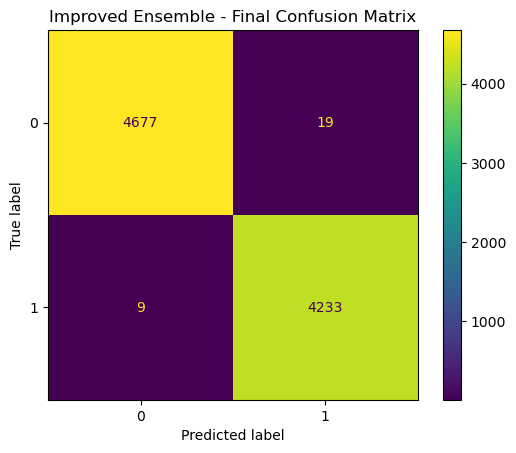

In [46]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

y_pred_final = ensemble_improved.predict(X_aug_test)
print(classification_report(y_test, y_pred_final))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final)
plt.title("Improved Ensemble - Final Confusion Matrix")
plt.show()


# Cross-Validation on Final Model

In [47]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, f1_score

cv_score = cross_val_score(ensemble_improved, X_aug_trainval, y_trainval, cv=5, scoring=make_scorer(f1_score))
print("Cross-Validated F1 Score (5-Fold):", np.mean(cv_score))

Cross-Validated F1 Score (5-Fold): 0.997202403105736


# Final Evaluation & Conclusion

✅ Final Model: Improved Ensemble (XGBoost + RF + Advanced Features)
              precision    recall  f1-score   support

           0      0.998     0.996     0.997      4696
           1      0.996     0.998     0.997      4242

    accuracy                          0.997      8938
   macro avg      0.997     0.997     0.997      8938
weighted avg      0.997     0.997     0.997      8938



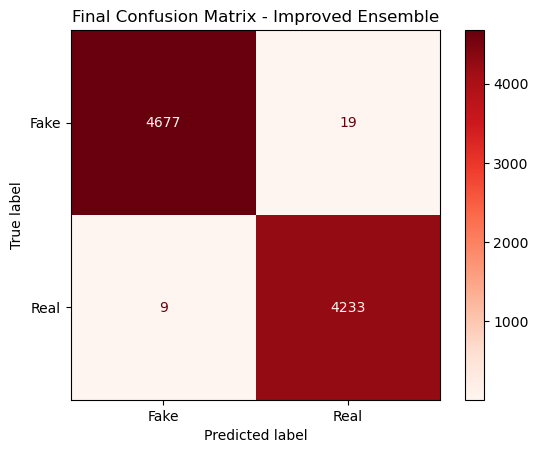

In [48]:
# Final test set prediction
final_preds = ensemble_improved.predict(X_aug_test)

# Report
print("✅ Final Model: Improved Ensemble (XGBoost + RF + Advanced Features)")
print(classification_report(y_test, final_preds, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, final_preds, display_labels=["Fake", "Real"], cmap="Reds")
plt.title("Final Confusion Matrix - Improved Ensemble")
plt.show()

In [49]:
print("- Cross-validated F1 score: {:.3f}".format(np.mean(cv_score)))

- Cross-validated F1 score: 0.997


# Results and conclusions

- **Final model:** weighted XGBoost + Random Forest ensemble with stylistic features (sentence counts, punctuation, casing) and auxiliary fake headlines.
- **Held-out test set:** F1 ≈ 0.997; 5-fold cross-validated F1 = 0.997.
- **The baseline was already strong.** The improved pipeline produced slightly *more* errors (19 false positives vs 12, 9 false negatives vs 7), so extra complexity did not pay off on this dataset.
- Near-perfect scores across all models suggest the dataset carries strong source/style artefacts (e.g. agency boilerplate in real articles), so these numbers should not be read as general fake-news detection ability.

## Next steps

- Ablate each improvement to find which one degraded performance.
- Remove source-specific artefacts (bylines, agency tags) and re-evaluate.
- Try trigrams and Optuna hyperparameter search; evaluate cross-dataset generalisation (e.g. LIAR).
